# JMH Benchmark Parser & Plotting Toolkit

This notebook provides:
1. A parser to extract datasets from JMH-style table output into typed arrays grouped by benchmark name.
2. Plotting helpers to compare **2, 3, 4, or 5** datasets on one chart.
3. A regression plotter that overlays a polynomial fit of configurable degree.

**Conventions**
- Parsed structure per benchmark: `List[Tuple[int, Tuple[float, float]]]` → `(size, (avg, error))`.
- `size` is taken from the filename part like `... 2_456chars.json ...` → `456`.
- Plot functions accept optional `output_folder` and `fmt` (`"svg"` or `"eps"`). If provided, figures are saved there.


In [17]:

# Imports (matplotlib only; seaborn intentionally not used)
from __future__ import annotations
import re
from typing import Dict, List, Tuple, Sequence, Iterable, Optional
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import os

def _ensure_save(fig, filename: Optional[str|Path], fmt: str = "svg", output_folder: Optional[str|Path] = None):
    """Save `fig` if `output_folder` is provided. Returns output path or None."""
    if output_folder is None:
        return None
    fmt = (fmt or "svg").lower()
    if fmt not in {"svg", "eps", "pdf", "png"}:
        raise ValueError(f"Unsupported format: {fmt!r}. Use 'svg', 'eps', 'pdf', or 'png'.")
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)
    filename = Path(filename) if filename is not None else Path("figure")
    outpath = output_folder / (filename.stem + f".{fmt}")
    fig.savefig(outpath, format=fmt, bbox_inches="tight", dpi=300)
    return outpath


In [18]:

def parse_jmh_table(raw_text: str) -> Dict[str, List[Tuple[int, Tuple[float, float]]]]:
    """Parse JMH-like '[info] Benchmark ...' table lines into datasets.

    Returns a dict mapping benchmark name → list of (size, (avg, error)).
    The list is sorted by size. Lines that don't match the expected table pattern are ignored.

    Expected columns pattern (loose, handles variable spacing):
      [info] <BenchmarkName> <file> <mode> [<cnt>] <score> [± <error>] <units>
    The Cnt column and the '± <error>' part are both optional: JMH leaves them
    blank when the benchmark is run with -i 1 (no error bar is computed).
    When the error is absent, it is reported as 0.0.

    Size extraction rule:
      Take the integer *immediately before* the 'chars' token in the filename.
      E.g., '102_23677chars.json' → 23677 ; '2_456chars.json' → 456.
    """
    datasets: Dict[str, List[Tuple[int, Tuple[float, float]]]] = {}

    # Regex for the table line
    line_re = re.compile(
        r"^\[info\]\s+"                                   # prefix
        r"(?P<bench>\S+)\s+"                              # benchmark name
        r"(?P<file>\S+)\s+"                               # filename token
        r"(?P<mode>\S+)\s+"                               # mode (e.g., avgt)
        r"(?:(?P<cnt>\d+)\s+)?"                           # optional Cnt (absent when -i 1)
        r"(?P<score>\d+(?:\.\d+)?)"                       # score (avg)
        r"(?:\s+±\s+(?P<error>\d+(?:\.\d+)?))?"           # optional '± <error>' (absent when -i 1)
        r"\s+(?P<units>\S+)\s*$"                          # units
    )

    # Extract the size found right before 'chars' inside the file token
    size_re = re.compile(r"_(?P<size>\d+)chars\b", re.IGNORECASE)

    for line in raw_text.splitlines():
        m = line_re.match(line)
        if not m:
            continue

        bench = m.group("bench")
        filetok = m.group("file")
        score = float(m.group("score"))
        error = float(m.group("error")) if m.group("error") else 0.0

        sm = size_re.search(filetok)
        if not sm:
            # If pattern fails, try to fallback to the last integer run in the token
            # (keeps the parser resilient for edge cases).
            m2 = re.search(r"(\d+)(?=\D*$)", filetok)
            if not m2:
                continue
            size = int(m2.group(1))
        else:
            size = int(sm.group("size"))

        datasets.setdefault(bench, []).append((size, (score, error)))

    # Sort each dataset by size
    for k in list(datasets.keys()):
        datasets[k].sort(key=lambda t: t[0])

    return datasets


In [19]:

from matplotlib import colors

def _clean_filename(s: str) -> str:
    filename_clean = s.replace("\n", "_").replace(" ", "_").replace("/", "_").replace(":", "_").replace(",", "_").replace(".", "_").replace("(", "_").replace(")", "_").replace("*", "-").replace("&", "and")
    changed = True
    while changed:
        new_clean = filename_clean.replace("__", "_")
        changed = (new_clean != filename_clean)
        filename_clean = new_clean
    return filename_clean

def _prep_xy(series: List[Tuple[int, Tuple[float, float]]]):
    xs = [s for s, _ in series]
    ys = [v[0] for _, v in series]
    yerr = [v[1] for _, v in series]
    return np.array(xs), np.array(ys), np.array(yerr)

# A list of easily distinguishable colors for colorblind-safe plots
_COLOR_CYCLE = [
    "#007bff",  # blue
    "#000000",  # black
    "#ff7f00",  # orange
    "#ff47a6",  # pink
    "#bdbd1d",  # yellow
    "#006354",  # teal
]

def _plot_many(datasets: Sequence[Tuple[str, List[Tuple[int, Tuple[float, float]]]]], 
               pretty_data_labels: Optional[Dict[str, str]] = None,
               title: Optional[str] = None,
               show_title: bool = False,
               output_folder: Optional[str|Path] = None,
               fmt: str = "svg",
               time_unit: str = "µs",
               convert_data_from_micro_sec: bool = False,
               filename: Optional[str|Path] = None,
               fontsize: int = -1,
               shape_cycle: Optional[List[str]] = None,
               color_cycle: List[str] = _COLOR_CYCLE,
               error_bars: bool = True,
               x_label: str = "Input size (chars)"):
    n = len(datasets)
    if n < 2 or n > 11:
        raise ValueError("_plot_many expects between 2 and 11 datasets.")
    
    factor = 1.0
    if convert_data_from_micro_sec:
        # We convert from µs to the desired time unit
        if time_unit == "ms":
            factor = 1e-3
        elif time_unit == "s":
            factor = 1e-6
        elif time_unit == "ns":
            factor = 1e3    
        elif time_unit == "µs":
            factor = 1.0
        else:
            raise ValueError(f"Unsupported time unit for conversion: {time_unit!r}. Use 'ns', 'µs', 'ms', or 's'.")


    fig, ax = plt.subplots(figsize=(7, 5))
    index = 0
    shape_cycle = shape_cycle or ['o']
    for label, series in datasets:
        xs, ys, yerr = _prep_xy(series)
        ys = ys * factor
        yerr = yerr * factor
        if pretty_data_labels and label in pretty_data_labels:
            label = pretty_data_labels[label]
        if not error_bars:
            yerr = None
        ax.errorbar(xs, ys, yerr=yerr, marker=shape_cycle[index % len(shape_cycle)], linestyle='', label=label, 
                    color=color_cycle[index % len(color_cycle)],
                    capsize=3)
        index += 1
    ax.set_xlabel(x_label)
    ax.set_ylabel(f"Time ({time_unit})")
    ax.grid(True, which='both', linestyle='--', alpha=0.4)
    if title and show_title:
        ax.set_title(title)
    else:
        print("Title: ", title)
    if fontsize > 0:
        ax.legend(fontsize=fontsize)
    else:
        ax.legend()

    filename_clean = _clean_filename((filename or (title or f"compare_{n}_datasets")))
    
    saved = _ensure_save(fig, filename_clean, fmt, output_folder)
    plt.show()
    return saved

def plot2(d1: Tuple[str, List[Tuple[int, Tuple[float, float]]]],
          d2: Tuple[str, List[Tuple[int, Tuple[float, float]]]],
          pretty_data_labels: Optional[Dict[str, str]] = None,
          title: Optional[str] = None,
          show_title: bool = False,
          output_folder: Optional[str|Path] = None,
          fmt: str = "svg",
          time_unit: str = "µs",
          convert_data_from_micro_sec: bool = False,
          filename: Optional[str|Path] = None,
          fontsize: int = -1,
          shape_cycle: Optional[List[str]] = None,
          error_bars: bool = True,
          color_cycle: List[str] = _COLOR_CYCLE,
          x_label: str = "Input size (chars)"):
    """Plot 2 datasets on the same axes."""
    return _plot_many([d1, d2], pretty_data_labels=pretty_data_labels, title=title, show_title=show_title, output_folder=output_folder, time_unit=time_unit, convert_data_from_micro_sec=convert_data_from_micro_sec, fmt=fmt, filename=filename, fontsize=fontsize, shape_cycle=shape_cycle, error_bars=error_bars, color_cycle=color_cycle, x_label=x_label)

def plot3(d1, d2, d3, title: Optional[str] = None,
          show_title: bool = False,
          pretty_data_labels: Optional[Dict[str, str]] = None,
          output_folder: Optional[str|Path] = None,
          fmt: str = "svg",
          time_unit: str = "µs",
          convert_data_from_micro_sec: bool = False,
          filename: Optional[str|Path] = None,
          fontsize: int = -1,
          shape_cycle: Optional[List[str]] = None,
          error_bars: bool = True,
          color_cycle: List[str] = _COLOR_CYCLE,
          x_label: str = "Input size (chars)"):
    """Plot 3 datasets on the same axes."""
    return _plot_many([d1, d2, d3], pretty_data_labels=pretty_data_labels, title=title, show_title=show_title, output_folder=output_folder, time_unit=time_unit, convert_data_from_micro_sec=convert_data_from_micro_sec, fmt=fmt, filename=filename, fontsize=fontsize, shape_cycle=shape_cycle, error_bars=error_bars, color_cycle=color_cycle, x_label=x_label)

def plot4(d1, d2, d3, d4, title: Optional[str] = None,
          show_title: bool = False,
          pretty_data_labels: Optional[Dict[str, str]] = None,
          output_folder: Optional[str|Path] = None,
          fmt: str = "svg",
          time_unit: str = "µs",
          convert_data_from_micro_sec: bool = False,
          filename: Optional[str|Path] = None,
          fontsize: int = -1,
          shape_cycle: Optional[List[str]] = None,
          error_bars: bool = True,
          color_cycle: List[str] = _COLOR_CYCLE,
          x_label: str = "Input size (chars)"):
    """Plot 4 datasets on the same axes."""
    return _plot_many([d1, d2, d3, d4], pretty_data_labels=pretty_data_labels, title=title, show_title=show_title, output_folder=output_folder, time_unit=time_unit, convert_data_from_micro_sec=convert_data_from_micro_sec, fmt=fmt, filename=filename, fontsize=fontsize, shape_cycle=shape_cycle, error_bars=error_bars, color_cycle=color_cycle, x_label=x_label)

def plot5(d1, d2, d3, d4, d5, title: Optional[str] = None,
          show_title: bool = False,
          pretty_data_labels: Optional[Dict[str, str]] = None,
          output_folder: Optional[str|Path] = None,
          fmt: str = "svg",
          time_unit: str = "µs",
          convert_data_from_micro_sec: bool = False,
          filename: Optional[str|Path] = None,
          fontsize: int = -1,
          shape_cycle: Optional[List[str]] = None,
          error_bars: bool = True,
          color_cycle: List[str] = _COLOR_CYCLE,
          x_label: str = "Input size (chars)"):
    """Plot 5 datasets on the same axes."""
    return _plot_many([d1, d2, d3, d4, d5], pretty_data_labels=pretty_data_labels, title=title, show_title=show_title, output_folder=output_folder, time_unit=time_unit, convert_data_from_micro_sec=convert_data_from_micro_sec, fmt=fmt, filename=filename, fontsize=fontsize, shape_cycle=shape_cycle, error_bars=error_bars, color_cycle=color_cycle, x_label=x_label)

def plot6(d1, d2, d3, d4, d5, d6, title: Optional[str] = None,
          show_title: bool = False,
          pretty_data_labels: Optional[Dict[str, str]] = None,
          output_folder: Optional[str|Path] = None,
          fmt: str = "svg",
          time_unit: str = "µs",
          convert_data_from_micro_sec: bool = False,
          filename: Optional[str|Path] = None, 
          fontsize: int = -1,
          shape_cycle: Optional[List[str]] = None,
          error_bars: bool = True,
          color_cycle: List[str] = _COLOR_CYCLE,
          x_label: str = "Input size (chars)"):
    """Plot 6 datasets on the same axes."""
    return _plot_many([d1, d2, d3, d4, d5, d6], pretty_data_labels=pretty_data_labels, title=title, show_title=show_title, output_folder=output_folder, time_unit=time_unit, convert_data_from_micro_sec=convert_data_from_micro_sec, fmt=fmt, filename=filename, fontsize=fontsize, shape_cycle=shape_cycle, error_bars=error_bars, color_cycle=color_cycle, x_label=x_label)

def plot7(d1, d2, d3, d4, d5, d6, d7, title: Optional[str] = None,
          show_title: bool = False,
          pretty_data_labels: Optional[Dict[str, str]] = None,
          output_folder: Optional[str|Path] = None,
          fmt: str = "svg",
          time_unit: str = "µs",
          convert_data_from_micro_sec: bool = False,
          filename: Optional[str|Path] = None,
          fontsize: int = -1,
          shape_cycle: Optional[List[str]] = None,
          error_bars: bool = True,
          color_cycle: List[str] = _COLOR_CYCLE,
          x_label: str = "Input size (chars)"):
    """Plot 7 datasets on the same axes."""
    return _plot_many([d1, d2, d3, d4, d5, d6, d7], pretty_data_labels=pretty_data_labels, title=title, show_title=show_title, output_folder=output_folder, time_unit=time_unit, convert_data_from_micro_sec=convert_data_from_micro_sec, fmt=fmt, filename=filename, fontsize=fontsize, shape_cycle=shape_cycle, error_bars=error_bars, color_cycle=color_cycle, x_label=x_label)

def plot8(d1, d2, d3, d4, d5, d6, d7, d8, title: Optional[str] = None,
          show_title: bool = False,
          pretty_data_labels: Optional[Dict[str, str]] = None,
          output_folder: Optional[str|Path] = None,
          fmt: str = "svg",
          time_unit: str = "µs",
          convert_data_from_micro_sec: bool = False,
          filename: Optional[str|Path] = None,
          fontsize: int = -1,
          shape_cycle: Optional[List[str]] = None,
          error_bars: bool = True,
          color_cycle: List[str] = _COLOR_CYCLE,
          x_label: str = "Input size (chars)"):
    """Plot 8 datasets on the same axes."""
    return _plot_many([d1, d2, d3, d4, d5, d6, d7, d8], pretty_data_labels=pretty_data_labels, title=title, show_title=show_title, output_folder=output_folder, time_unit=time_unit, convert_data_from_micro_sec=convert_data_from_micro_sec, fmt=fmt, filename=filename, fontsize=fontsize, shape_cycle=shape_cycle, error_bars=error_bars, color_cycle=color_cycle, x_label=x_label)

def plot9(d1, d2, d3, d4, d5, d6, d7, d8, d9, title: Optional[str] = None,
          show_title: bool = False,
          pretty_data_labels: Optional[Dict[str, str]] = None,
          output_folder: Optional[str|Path] = None,
          fmt: str = "svg",
          time_unit: str = "µs",
          convert_data_from_micro_sec: bool = False,
          filename: Optional[str|Path] = None,
          fontsize: int = -1,
          shape_cycle: Optional[List[str]] = None,
          error_bars: bool = True,
          color_cycle: List[str] = _COLOR_CYCLE,
          x_label: str = "Input size (chars)"):
    """Plot 9 datasets on the same axes."""
    return _plot_many([d1, d2, d3, d4, d5, d6, d7, d8, d9], pretty_data_labels=pretty_data_labels, title=title, show_title=show_title, output_folder=output_folder, time_unit=time_unit, convert_data_from_micro_sec=convert_data_from_micro_sec, fmt=fmt, filename=filename, fontsize=fontsize, shape_cycle=shape_cycle, error_bars=error_bars, color_cycle=color_cycle, x_label=x_label)

def plot10(d1, d2, d3, d4, d5, d6, d7, d8, d9, d10, title: Optional[str] = None,
           show_title: bool = False,
           pretty_data_labels: Optional[Dict[str, str]] = None,
           output_folder: Optional[str|Path] = None,
           fmt: str = "svg",
           time_unit: str = "µs",
           convert_data_from_micro_sec: bool = False,
           filename: Optional[str|Path] = None,
           fontsize: int = -1,
           shape_cycle: Optional[List[str]] = None,
           error_bars: bool = True,
           color_cycle: List[str] = _COLOR_CYCLE,
           x_label: str = "Input size (chars)"):
    """Plot 10 datasets on the same axes."""
    return _plot_many([d1, d2, d3, d4, d5, d6, d7, d8, d9, d10], pretty_data_labels=pretty_data_labels, title=title, show_title=show_title, output_folder=output_folder, time_unit=time_unit, convert_data_from_micro_sec=convert_data_from_micro_sec, fmt=fmt, filename=filename, fontsize=fontsize, shape_cycle=shape_cycle, error_bars=error_bars, color_cycle=color_cycle, x_label=x_label)

def plot11(d1, d2, d3, d4, d5, d6, d7, d8, d9, d10, d11, title: Optional[str] = None,
           show_title: bool = False,
           pretty_data_labels: Optional[Dict[str, str]] = None,
           output_folder: Optional[str|Path] = None,
           fmt: str = "svg",
           time_unit: str = "µs",
           convert_data_from_micro_sec: bool = False,
           filename: Optional[str|Path] = None,
           fontsize: int = -1,
           shape_cycle: Optional[List[str]] = None,
           error_bars: bool = True,
           color_cycle: List[str] = _COLOR_CYCLE,
           x_label: str = "Input size (chars)"):
    """Plot 11 datasets on the same axes."""
    return _plot_many([d1, d2, d3, d4, d5, d6, d7, d8, d9, d10, d11], pretty_data_labels=pretty_data_labels, title=title, show_title=show_title, output_folder=output_folder, time_unit=time_unit, convert_data_from_micro_sec=convert_data_from_micro_sec, fmt=fmt, filename=filename, fontsize=fontsize, shape_cycle=shape_cycle, error_bars=error_bars, color_cycle=color_cycle, x_label=x_label)

In [20]:

def _print_poly(poly: np.poly1d):
    equation = ""
    degree = len(poly.coeffs) - 1
    for i, coeff in enumerate(poly.coeffs):
        power = degree - i
        coeff_abs = abs(coeff)
        if coeff < 0:
            equation += " - "
        else:
            if i > 0:
                equation += " + "
        if power == 0:
            equation += f"{coeff_abs:.4g}"
        elif power == 1:
            equation += f"{coeff_abs:.4g}*x"
        else:
            equation += f"{coeff_abs:.4g}*x^{power}"
    print(f"Polynomial function f(x) = {equation}")

def plot_with_regression(dataset: Tuple[str, List[Tuple[int, Tuple[float, float]]]],
                         degree: int | str = 1,
                         title: Optional[str] = None,
                         show_title: bool = False,
                         color: Optional[str] = None,
                         pretty_data_labels: Optional[Dict[str, str]] = None,
                         output_folder: Optional[str|Path] = None,
                         fmt: str = "svg",
                         time_unit: str = "µs",
                         custom_additional_y_label: str = "",
                         convert_data_from_micro_sec: bool = False,
                         filename: Optional[str|Path] = None,
                         fontsize: int = -1):
    """Plot a dataset with error bars and overlay a polynomial regression of given degree.

    Parameters
    ----------
    dataset : (name, series) where series is List[(size, (avg, error))].
    degree : polynomial degree (>= 0). degree "nlogn" is used for n log n regression.
    title : optional str for the plot title.
    output_folder : optional path to save the plot.
    fmt : 'svg' or 'eps' (default: 'svg').
    filename : optional filename stem for saving.
    """
    if (isinstance(degree, int) and degree < 0) or (isinstance(degree, str) and degree != "nlogn"):
        raise ValueError("degree must be >= 0")
    
    factor = 1.0
    if convert_data_from_micro_sec:
        # We convert from µs to the desired time unit
        if time_unit == "ms":
            factor = 1e-3
        elif time_unit == "s":
            factor = 1e-6
        elif time_unit == "ns":
            factor = 1e3    
        elif time_unit == "µs":
            factor = 1.0
        else:
            raise ValueError(f"Unsupported time unit for conversion: {time_unit!r}. Use 'ns', 'µs', 'ms', or 's'.")

    
    label, series = dataset
    xs, ys, yerr = _prep_xy(series)
    
    ys = ys * factor
    yerr = yerr * factor

        # Fit polynomial
    if degree == "nlogn":
        # Model: y = a*(x log2 x) + b
        if np.any(xs <= 0):
            raise ValueError("n log n regression requires all x values to be > 0")

        xs_transformed = xs * np.log2(xs)
        coeffs = np.polyfit(xs_transformed, ys, deg=1)
        poly = np.poly1d(coeffs)

        # Smooth line over the observed range
        xfit = np.linspace(xs.min(), xs.max(), 500)
        xfit_transformed = xfit * np.log2(xfit)
        yfit = poly(xfit_transformed)

        reg_label = "a*(n log2 n) + b"
    else:
        coeffs = np.polyfit(xs, ys, deg=degree)
        poly = np.poly1d(coeffs)

        # Smooth line over the observed range
        xfit = np.linspace(xs.min(), xs.max(), 500)
        yfit = poly(xfit)

        if isinstance(degree, int) and degree == 1:
            reg_label = f"Linear regression"
        else:
            reg_label = f"Polynomial of degree {degree}"

    if color is None:
        color = _COLOR_CYCLE[0]
    fig, ax = plt.subplots(figsize=(7, 5))
    if pretty_data_labels and label in pretty_data_labels:
            label = pretty_data_labels[label]
    ax.errorbar(xs, ys, yerr=yerr, marker='o', color=color, linestyle='--', label=f"{label}")
    ax.plot(xfit, yfit, label=reg_label, color='gray')
    ax.set_xlabel("Input size (chars)" + custom_additional_y_label)
    ax.set_ylabel(f"Time ({time_unit})")
    ax.grid(True, which='both', linestyle='--', alpha=0.4)
    if fontsize > 0:
        ax.legend(fontsize=fontsize)
    else:
        ax.legend()
    if title and show_title:
        ax.set_title(title)
    else:
        print("Title: ", title)

    filename_clean = _clean_filename((filename or (title or f"regression_deg{degree}_{label}")))

    saved = _ensure_save(fig, filename_clean, fmt, output_folder)
    plt.show()

    if degree == 1.5:
        a, b = poly.coeffs  # since deg=1
        print(f"n log n function f(n) = {a:.4g}*(n*log2(n)) + {b:.4g}")
    else:
        _print_poly(poly)
    return saved


def plot_distribution(data: Iterable[float],
                      title: Optional[str] = None,
                      show_title: bool = False,
                      x_label: Optional[str] = None,
                      y_label: Optional[str] = None,
                      output_folder: Optional[str|Path] = None,
                      fmt: str = "svg",
                      bins: int = 30,
                      log_scale: bool = False,
                      filename: Optional[str|Path] = None,
                      fontsize: int = -1):
    """Plot a histogram distribution of the provided data."""
    fig, ax = plt.subplots(figsize=(7, 5))
    color = _COLOR_CYCLE[0]
    if log_scale:
        ax.set_yscale('log')
    ax.hist(data, bins=bins, color=color, alpha=0.7, edgecolor='black')
    if x_label:
        ax.set_xlabel(x_label)
    else:
        ax.set_xlabel("Value")
    if y_label:
        ax.set_ylabel(y_label)
    else:
        ax.set_ylabel("Frequency")
    ax.grid(True, which='both', linestyle='--', alpha=0.4)
    if title and show_title:
        ax.set_title(title)
    else:
        print("Title: ", title)
    if fontsize > 0:
        ax.legend(fontsize=fontsize)

    filename_clean = _clean_filename((filename or (title or "distribution_histogram")))

    saved = _ensure_save(fig, filename_clean, fmt, output_folder)
    plt.show()
    return saved



### Usage
```python
raw = """<paste your JMH output here>"""
data = parse_jmh_table(raw)

# Example: build tuples for plotting
bench1 = "JsonLexerBenchmark.lex_ZipperMem"
bench2 = "JsonLexerBenchmark.separability_pred"
d1 = (bench1, data[bench1])
d2 = (bench2, data[bench2])

# Compare two datasets
plot2(d1, d2, title="Lex vs Separability", output_folder="plots", fmt="svg")

# Regression for one dataset
plot_with_regression(d2, degree=1, title="Separability: Linear Fit", output_folder="plots", fmt="svg")
```


In [21]:
# delete the 'plots' output folder
if os.path.exists("plots"):
    import shutil
    shutil.rmtree("plots")

# JSON Manipulation Benchmark Results

Title:  JSON Sorting: Recombining With vs Without Wrapper


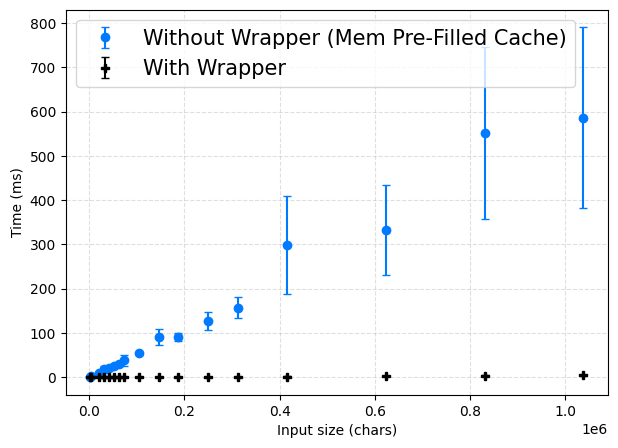

Title:  JSON Sorting: Lex and R-Path sep vs Lex Only (Mem) V3


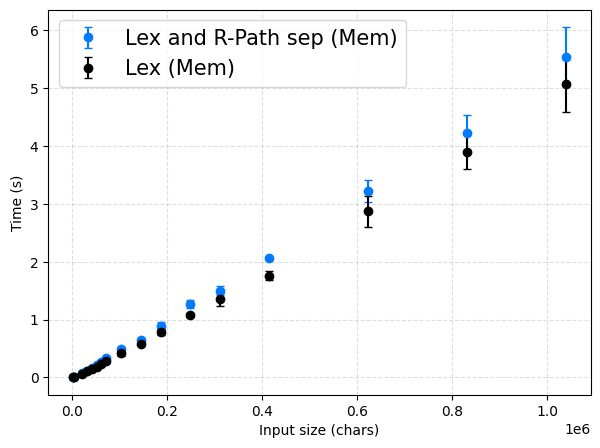

PosixPath('plots/fig_5_left_lex_and_check_printable_vs_lex.pdf')

In [22]:
latest_folder = Path("./latest")
json_manipulation_file = None
for entry in os.listdir(latest_folder):
    if 'json_manipulation' in entry.lower():
        json_manipulation_file = latest_folder / entry
        break

# If found, parse and plot
assert json_manipulation_file is not None, "No json_manipulation file found in latest folder."
with open(json_manipulation_file, "r") as f:
  raw3 = f.read()
  data3 = parse_jmh_table(raw3)

benchRecombineWithoutWrapper = "JsonManipulationBenchmark.checkPredicateAndRecombineWithoutWrapper"
benchLex = "JsonManipulationBenchmark.lex"
benchLexV1 = "JsonManipulationBenchmark.lexV1"
benchLexV1NonMem = "JsonManipulationBenchmark.lexV1NonMem"
benchLexAndCheckPrintableV1 = "JsonManipulationBenchmark.lexAndCheckPrintableV1"
benchLexAndCheckPrintableV3 = "JsonManipulationBenchmark.lexAndCheckPrintableV3"
benchRecombineSlices = "JsonManipulationBenchmark.recombineSlices"
benchSliceAndSort = "JsonManipulationBenchmark.sliceAndSort"
benchCheckPrintableNonMem = "JsonManipulationBenchmark.checkPrintableNonMem"
benchCheckPrintable = "JsonManipulationBenchmark.checkPrintableMemPreFilledCache"

pretty_labels = {
      benchRecombineWithoutWrapper: "Without Wrapper (Mem Pre-Filled Cache)",
      benchLex: "Lex (Mem)",
      benchLexV1: "Lex V1 (Mem)",
      benchLexV1NonMem: "Lex V1 (Non-Mem)",
      # benchLexV2NonMem: "Lex V2 (Non-Mem)",
      benchLexAndCheckPrintableV1: "Lex and R-Path sep V1 (Mem)",
      benchLexAndCheckPrintableV3: "Lex and R-Path sep (Mem)",
      benchRecombineSlices: "With Wrapper",
      benchSliceAndSort: "Slice and Sort",
      benchCheckPrintableNonMem: "R-Path sep (Non-Mem)",
      benchCheckPrintable: "R-Path sep (Mem Pre-Filled Cache)"
}

plot2((benchRecombineWithoutWrapper, data3[benchRecombineWithoutWrapper]),
      (benchRecombineSlices, data3[benchRecombineSlices]),
      title="JSON Sorting: Recombining With vs Without Wrapper",
      filename="fig_5_right_recombine_with_vs_without_wrapper",
      show_title=False,
      pretty_data_labels=pretty_labels,
      output_folder="plots",
      time_unit="ms",
      convert_data_from_micro_sec=True,
      shape_cycle=['o', 'P'],
      fmt="pdf",
      fontsize=15)

plot2((benchLexAndCheckPrintableV3, data3[benchLexAndCheckPrintableV3]),
      (benchLex, data3[benchLex]),
      title="JSON Sorting: Lex and R-Path sep vs Lex Only (Mem) V3",
      filename="fig_5_left_lex_and_check_printable_vs_lex",
      show_title=False,
      pretty_data_labels=pretty_labels,
      output_folder="plots",
      time_unit="s",
      convert_data_from_micro_sec=True,
      fmt="pdf",
      fontsize=15)



# Coqlex Comparison Benchmark Results

In [23]:
# --- Build { system_name: [(num_chars, time_seconds), ...] } from your results folder ---

from pathlib import Path
import json
from collections import defaultdict

def load_benchmark_dict(base_dir: str | Path) -> dict[str, list[tuple[int, float]]]:
    """
    Walks `base_dir`, where each immediate subfolder is a system (e.g., CoqLex, ZipLex, ...),
    and each contains JSON files with fields:
        {
          "fname": "162.json",
          "input_len": 37599,
          "times": [0.01234],
          "rest_len": 0,
          "sem_tokens_len": "Some 11664"
        }
    Returns:
        dict: { system_name: [(input_len, time_seconds), ...] } sorted by input_len
    """
    base = Path(base_dir).expanduser().resolve()
    if not base.is_dir():
        raise NotADirectoryError(f"'{base}' is not a directory")

    data = defaultdict(list)

    for system_dir in sorted([p for p in base.iterdir() if p.is_dir()]):
        system_name = system_dir.name
        for jf in sorted(system_dir.glob("*.json")):
            try:
                with jf.open("r", encoding="utf-8") as f:
                    obj = json.load(f)
                input_len = int(obj["input_len"])
                times_list = obj.get("times", [])
                if not times_list:
                    continue  # skip if no timing present
                time_seconds = float(times_list[0])  # your pipeline stores seconds already
                data[system_name].append((input_len, (time_seconds, 0.0)))  # no error info available
            except Exception as e:
                # keep going if one file is malformed
                print(f"[warn] Skipping {jf}: {e}")

    # sort each system's tuples by input size for easier plotting later
    for k in list(data.keys()):
        data[k] = sorted(data[k], key=lambda t: t[0])

    return dict(data)

RESULTS_ROOT = "from_coqlex/Comparison/JSON/results"  

bench_dict = load_benchmark_dict(RESULTS_ROOT)

# quick sanity check
for system, pairs in bench_dict.items():
    print(f"{system}: {len(pairs)} entries; first few -> {pairs[:3]}")


CoqLex: 13 entries; first few -> [(456, (0.0004, 0.0)), (5115, (0.00433, 0.0)), (9755, (0.00916, 0.0))]
Verbatim: 13 entries; first few -> [(456, (1.84885, 0.0)), (5115, (2.17992, 0.0)), (9755, (2.50017, 0.0))]
VerbatimSC: 13 entries; first few -> [(456, (1.94841, 0.0)), (5115, (2.32172, 0.0)), (9755, (2.6682, 0.0))]
VerbatimSt: 13 entries; first few -> [(456, (1.89054, 0.0)), (5115, (2.14848, 0.0)), (9755, (2.45933, 0.0))]
ZipLex: 13 entries; first few -> [(456, (0.0008518859999999999, 0.0)), (5115, (0.01131786, 0.0)), (9755, (0.022845327000000002, 0.0))]
ZiplexGraal: 13 entries; first few -> [(456, (0.000710951, 0.0)), (5115, (0.009236216, 0.0)), (9755, (0.019166659, 0.0))]
ZiplexMemDeriv: 13 entries; first few -> [(456, (0.0006295, 0.0)), (5115, (0.008716973, 0.0)), (9755, (0.020143054, 0.0))]
ZiplexMemDerivGraal: 13 entries; first few -> [(456, (0.00042428699999999997, 0.0)), (5115, (0.006233415, 0.0)), (9755, (0.012273863, 0.0))]
ZiplexNoMem: 13 entries; first few -> [(456, (0.000

Title:  JSON Lexing: CoqLex vs ZipLex vs OCamllex vs Verbatim Variants


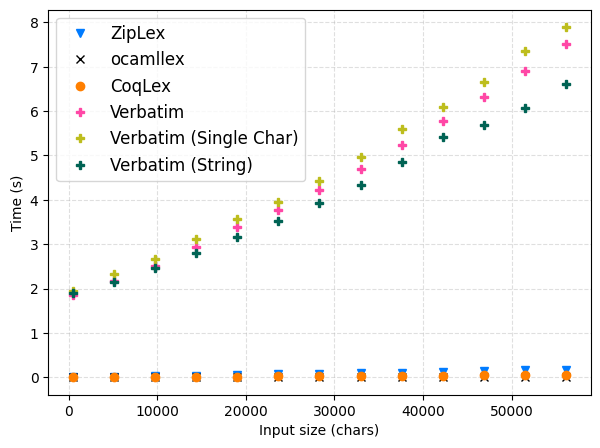

Title:  JSON Lexing: CoqLex vs ZipLex Mem variants vs OCamllex


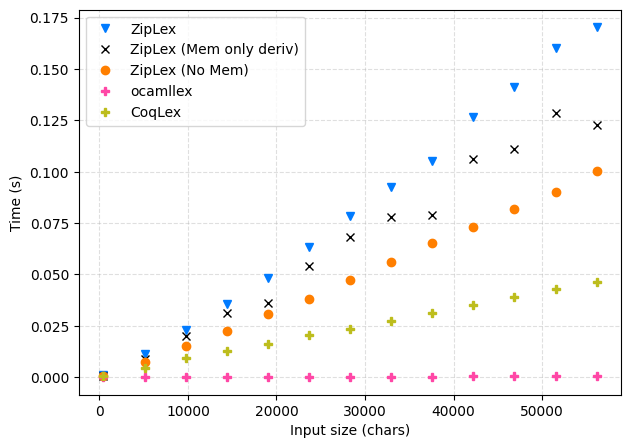

Title:  JSON Lexing: ZipLex variants vs Graal vs CoqLex vs OCamllex


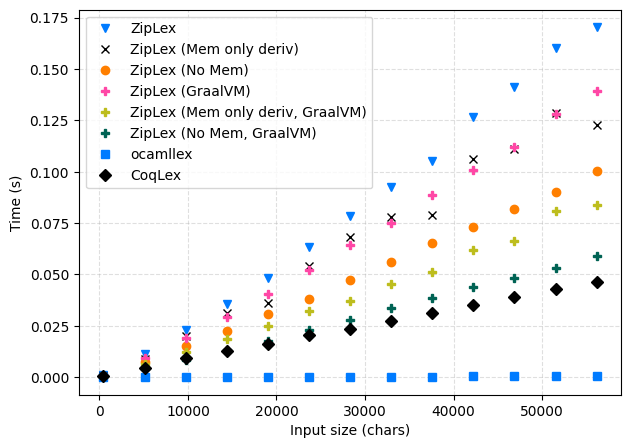

Title:  JSON Lexing: ZipLex variants vs Graal vs CoqLex vs OCamllex


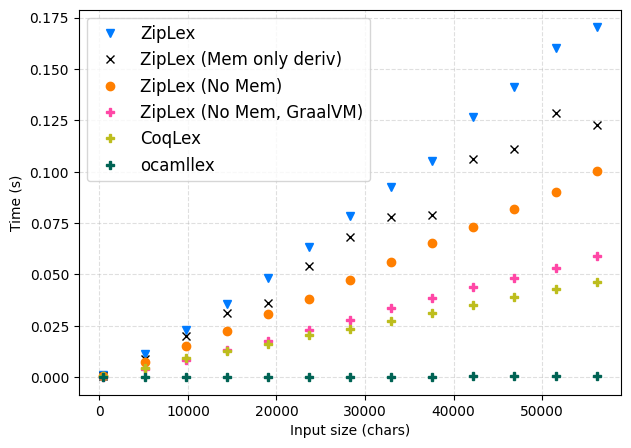


Largest input size data points:
CoqLex               | Input Size:   56154 chars | Time: 0.0462 s
Verbatim             | Input Size:   56154 chars | Time: 7.5050 s
VerbatimSC           | Input Size:   56154 chars | Time: 7.8924 s
VerbatimSt           | Input Size:   56154 chars | Time: 6.6218 s
ZipLex               | Input Size:   56154 chars | Time: 0.1703 s
ZiplexGraal          | Input Size:   56154 chars | Time: 0.1390 s
ZiplexMemDeriv       | Input Size:   56154 chars | Time: 0.1227 s
ZiplexMemDerivGraal  | Input Size:   56154 chars | Time: 0.0840 s
ZiplexNoMem          | Input Size:   56154 chars | Time: 0.1005 s
ZiplexNoMemGraal     | Input Size:   56154 chars | Time: 0.0592 s
ocamllex             | Input Size:   56154 chars | Time: 0.0004 s


In [24]:
plot6(
    ("ZipLex", bench_dict["ZipLex"]),
    ("ocamllex", bench_dict["ocamllex"]),
    ("CoqLex", bench_dict["CoqLex"]),
    ("Verbatim", bench_dict["Verbatim"]),
    ("VerbatimSC", bench_dict["VerbatimSC"]),
    ("VerbatimSt", bench_dict["VerbatimSt"]),
    title="JSON Lexing: CoqLex vs ZipLex vs OCamllex vs Verbatim Variants",
    filename="fig_6_left_json_lexing_comparison_all_systems",
    pretty_data_labels={
        "CoqLex": "CoqLex",
        "Verbatim": "Verbatim",
        "VerbatimSC": "Verbatim (Single Char)",
        "VerbatimSt": "Verbatim (String)",
        "ZipLex": "ZipLex",
        "ZiplexMemDeriv": "ZipLex (Mem only deriv)",
        "ZiplexNoMem": "ZipLex (No Mem)",
        "ocamllex": "ocamllex"
    },
    shape_cycle= [
        'v',
        'x',
        'o',
        'P',
        'P',
        'P',
    ],
    time_unit="s",
    output_folder="plots",
    fmt="pdf",
    fontsize=12,
    error_bars=False
)

plot5(
    ("ZipLex", bench_dict["ZipLex"]),
    ("ZipLexMemDeriv", bench_dict["ZiplexMemDeriv"]),
    ("ZipLexNoMem", bench_dict["ZiplexNoMem"]),
    ("ocamllex", bench_dict["ocamllex"]),
    ("CoqLex", bench_dict["CoqLex"]),
    title="JSON Lexing: CoqLex vs ZipLex Mem variants vs OCamllex",
    # filename="fig_7_left_ziplex_mem_variants_vs_coqlex_vs_ocamllex",
    filename=None,
    pretty_data_labels={
        "CoqLex": "CoqLex",
        "Verbatim": "Verbatim",
        "VerbatimSC": "Verbatim (Single Char)",
        "VerbatimSt": "Verbatim (String)",
        "ZipLex": "ZipLex",
        "ZipLexMemDeriv": "ZipLex (Mem only deriv)",
        "ZipLexNoMem": "ZipLex (No Mem)",
        "ocamllex": "ocamllex"
    },
    shape_cycle= [
        'v',
        'x',
        'o',
        'P',
        'P',
        'P',
    ],
    time_unit="s",
    output_folder="plots",
    fmt="pdf",
    error_bars=False
)

plot8(
    ("ZipLex", bench_dict["ZipLex"]),
    ("ZipLexMemDeriv", bench_dict["ZiplexMemDeriv"]),
    ("ZipLexNoMem", bench_dict["ZiplexNoMem"]),
    ("ZiplexGraal", bench_dict["ZiplexGraal"]),
    ("ZiplexMemDerivGraal", bench_dict["ZiplexMemDerivGraal"]),
    ("ZiplexNoMemGraal", bench_dict["ZiplexNoMemGraal"]),
    ("ocamllex", bench_dict["ocamllex"]),
    ("CoqLex", bench_dict["CoqLex"]),
    title="JSON Lexing: ZipLex variants vs Graal vs CoqLex vs OCamllex",
    # filename="fig_7_left_graal_vs_ziplex_variants_vs_coqlex_vs_ocamllex",
    filename=None,
    pretty_data_labels={
        "CoqLex": "CoqLex",
        "ZipLex": "ZipLex",
        "ZipLexMemDeriv": "ZipLex (Mem only deriv)",
        "ZipLexNoMem": "ZipLex (No Mem)",
        "ZiplexGraal": "ZipLex (GraalVM)",
        "ZiplexMemDerivGraal": "ZipLex (Mem only deriv, GraalVM)",
        "ZiplexNoMemGraal": "ZipLex (No Mem, GraalVM)",
        "ocamllex": "ocamllex"
    },
    shape_cycle=['v', 'x', 'o', 'P', 'P', 'P', 's', 'D'],
    time_unit="s",
    output_folder="plots",
    fmt="pdf",
    error_bars=False
)

plot6(
    ("ZipLex", bench_dict["ZipLex"]),
    ("ZipLexMemDeriv", bench_dict["ZiplexMemDeriv"]),
    ("ZipLexNoMem", bench_dict["ZiplexNoMem"]),
    # ("ZiplexGraal", bench_dict["ZiplexGraal"]),
    # ("ZiplexMemDerivGraal", bench_dict["ZiplexMemDerivGraal"]),
    ("ZiplexNoMemGraal", bench_dict["ZiplexNoMemGraal"]),
    ("CoqLex", bench_dict["CoqLex"]),
    ("ocamllex", bench_dict["ocamllex"]),
    title="JSON Lexing: ZipLex variants vs Graal vs CoqLex vs OCamllex",
    filename="fig_7_left_graal_vs_ziplex_variants_vs_coqlex_vs_ocamllex",
    fontsize=12,
    pretty_data_labels={
        "CoqLex": "CoqLex",
        "ZipLex": "ZipLex",
        "ZipLexMemDeriv": "ZipLex (Mem only deriv)",
        "ZipLexNoMem": "ZipLex (No Mem)",
        "ZiplexGraal": "ZipLex (GraalVM)",
        "ZiplexMemDerivGraal": "ZipLex (Mem only deriv, GraalVM)",
        "ZiplexNoMemGraal": "ZipLex (No Mem, GraalVM)",
        "ocamllex": "ocamllex"
    },
    shape_cycle=['v', 'x', 'o', 'P', 'P', 'P', 's', 'D'],
    time_unit="s",
    output_folder="plots",
    fmt="pdf",
    error_bars=False
)

# Print the data points for the highest X value for each system to check the largest input size performance
# in a table format
print("\nLargest input size data points:")
for system, pairs in bench_dict.items():
    if pairs:
        largest_input, (time_sec, _) = pairs[-1]
        print(f"{system:20s} | Input Size: {largest_input:7d} chars | Time: {time_sec:.4f} s")

# A and A*B Lexer Benchmark Results

In [25]:
# --- Flex (hyperfine) JSON ingestion: latest/flex/*.json -> list[(size, (mean, err_99_9_ci))] ---

from pathlib import Path
import json
import math
import re

FLEX_DIR = Path("latest/flex")  # adjust if needed
assert FLEX_DIR.exists(), f"Flex results folder not found: {FLEX_DIR.resolve()}"

# Unit scaling: hyperfine reports seconds. Set to 1e6 for microseconds, 1e3 for ms, 1 for seconds.
SCALE = 1e6
UNIT = "µs"

# 99.9% two-sided CI => alpha = 0.001
ALPHA = 0.001

def _t_crit_2sided_999(df: int) -> float:
    """
    Two-sided 99.9% t critical value with df degrees of freedom.
    Uses SciPy if available; otherwise falls back to normal approx (conservative-ish for df>=9).
    """
    try:
        from scipy.stats import t  # type: ignore
        return float(t.ppf(1 - ALPHA / 2, df))
    except Exception:
        # Normal approx for 99.9% two-sided
        return 3.290526731

def _parse_size_from_name(p: Path) -> int:
    # expects flex_<size>.json, where <size> may be "500" or "500.0"
    m = re.match(r"flex_(.+)\.json$", p.name)
    if not m:
        raise ValueError(f"Unexpected filename: {p.name}")
    s = float(m.group(1))
    return int(s) if s.is_integer() else int(round(s))

flex_results = []  # list[(size, (mean, err))]
flex_results_dict = {}  # dict[size] = (mean, err)

for jp in sorted(FLEX_DIR.glob("flex_*.json")):
    with open(jp, "r") as f:
        payload = json.load(f)

    r = payload["results"][0]
    times = r.get("times", [])
    n = len(times) if times else None

    mean_s = float(r["mean"])
    std_s = float(r.get("stddev", 0.0))

    # If stddev missing/zero but we have times, compute sample stddev.
    if (std_s == 0.0) and times and len(times) >= 2:
        m = sum(times) / len(times)
        var = sum((x - m) ** 2 for x in times) / (len(times) - 1)
        std_s = math.sqrt(var)

    # 99.9% CI half-width: t * s / sqrt(n)
    if times and len(times) >= 2:
        tcrit = _t_crit_2sided_999(len(times) - 1)
        err_s = tcrit * std_s / math.sqrt(len(times))
    else:
        err_s = float("nan")

    size = _parse_size_from_name(jp)
    mean = mean_s * SCALE
    err = err_s * SCALE

    flex_results.append((size, (mean, err)))
    flex_results_dict[size] = (mean, err)

flex_results.sort(key=lambda x: x[0])

print(f"Loaded {len(flex_results)} flex JSON files from {FLEX_DIR.resolve()}")
print(f"Units: {UNIT} (SCALE={SCALE})")
flex_results


Loaded 48 flex JSON files from /Users/samuel/EPFL/bolts/lexers/regex/ziplex/benchmark_results/latest/flex
Units: µs (SCALE=1000000.0)


[(100, (801.9711400000002, 410.9400380241799)),
 (200, (776.0046600000004, 348.2078333241183)),
 (300, (989.7185399999998, 758.7981209819161)),
 (500, (471.5713199999998, 19.83252576292452)),
 (500, (1422.07672, 488.58827293589036)),
 (800, (2346.0593400000007, 481.4585972675793)),
 (1000, (3398.3378000000007, 665.3244795708779)),
 (1200, (4387.63328, 304.10367066992984)),
 (2000, (11143.786300000002, 803.6838287800873)),
 (2500, (16597.02392, 610.9192298318244)),
 (5000, (63220.332220000026, 706.168980769814)),
 (10000, (245358.13484, 650.1305152333916)),
 (12500, (381813.67308000004, 457.66021729763105)),
 (15000, (548182.23184, 459.25847576577394)),
 (17500, (745231.4447800001, 348.7726465609227)),
 (20000, (973094.30292, 822.3490430979599)),
 (22500, (1231452.7399000004, 2448.1317516641434)),
 (25000, (1518155.3880600003, 656.9135613175994)),
 (27500, (1836308.9066800005, 473.5718863760061)),
 (30000, (2185193.6897400003, 651.2735972799949)),
 (32500, (2565030.36032, 3506.526600499

In [26]:
# Load coqles a and a*b results

RESULTS_ROOT_AASTARB = "from_coqlex/Comparison/AAStarB/results"
res = load_benchmark_dict(RESULTS_ROOT_AASTARB)
coqlex_aastar_b = res["CoqLex"]
verbatim_aastar_b = res["Verbatim"]

# Convert time in seconds to µs
coqlex_aastar_b = [(size, (time_sec * 1e6, err * 1e6)) for size, (time_sec, err) in coqlex_aastar_b]
print(f"coqlex_aastar_b: {coqlex_aastar_b}")
verbatim_aastar_b = [(size, (time_sec * 1e6, err * 1e6)) for size, (time_sec, err) in verbatim_aastar_b]
print(f"verbatim_aastar_b: {verbatim_aastar_b}")

coqlex_aastar_b: [(100, (110.0, 0.0)), (200, (490.0, 0.0)), (300, (1120.0, 0.0)), (500, (3020.0, 0.0)), (800, (8280.0, 0.0)), (1000, (12620.0, 0.0)), (1200, (18280.0, 0.0)), (2000, (52260.0, 0.0)), (2500, (79760.0, 0.0)), (5000, (327760.0, 0.0)), (10000, (1369000.0, 0.0)), (12500, (2195910.0, 0.0)), (15000, (3226130.0, 0.0)), (17500, (4604760.0, 0.0)), (20000, (6166070.0, 0.0)), (22500, (7918900.0, 0.0)), (25000, (10400190.0, 0.0)), (27500, (13104360.0, 0.0)), (30000, (15415130.0, 0.0)), (32500, (18883020.0, 0.0)), (35000, (22235750.0, 0.0)), (37500, (26058840.0, 0.0)), (40000, (30953010.0, 0.0)), (42500, (34901260.0, 0.0)), (45000, (39498200.0, 0.0)), (47500, (46065530.0, 0.0)), (50000, (50357560.0, 0.0)), (52500, (57909380.0, 0.0)), (55000, (65194390.0, 0.0)), (57500, (72588140.0, 0.0)), (60000, (78408690.0, 0.0)), (62500, (85915110.0, 0.0)), (65000, (94846540.0, 0.0)), (67500, (108986120.0, 0.0)), (70000, (113958010.0, 0.0)), (72500, (127383140.0, 0.0)), (75000, (138069750.0, 0.0)),

dict_keys(['AAStarBLexerBenchmark.lex_Silex', 'AAStarBLexerBenchmark.lex_ZipperV2Mem', 'AAStarBLexerBenchmark.lex_ZipperV3Mem'])
Title:  a & a*b: ZipLex vs Flex vs Coqlex vs Verbatim


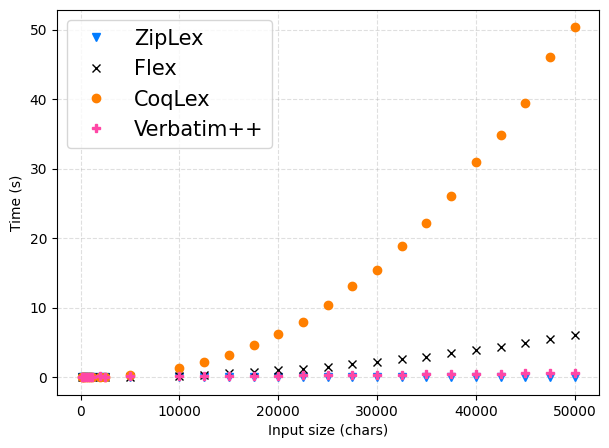

Title:  a & a*b: ZipLex vs Verbatim


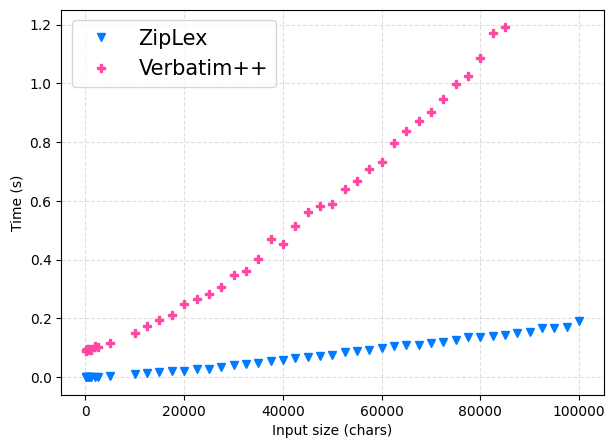

PosixPath('plots/fig_4_right_a_aStarb_ziplex_verbatim_pdf.pdf')

In [27]:
latest_folder = Path("./latest")
aastarb_lexer_file = None
for entry in os.listdir(latest_folder):
    if 'aa_star_b_lexer_benchmark_wi' in entry.lower():
        aastarb_lexer_file = latest_folder / entry
        break
    
assert aastarb_lexer_file is not None, "Could not find aastarb_lexer benchmark file in 'latest' folder."

with open(aastarb_lexer_file, "r") as f:
    raw6 = f.read()
data6 = parse_jmh_table(raw6)
print(data6.keys())

bench_aastarb_zipperMem = "AAStarBLexerBenchmark.lex_ZipperV3Mem"
bench_aastarb_zipperV1Mem = "AAStarBLexerBenchmark.lex_ZipperV1Mem"
bench_aastarb_zipperMemV2 = "AAStarBLexerBenchmark.lex_ZipperV2Mem"
bench_aastarb_silex = "AAStarBLexerBenchmark.lex_Silex"

# if bench_aastarb_zipperMem in data6 and bench_aastarb_zipperV1Mem in data6 and bench_aastarb_zipperMemV2OnlyDeriv in data6:
d_aastarb_zipperMem = (bench_aastarb_zipperMem, data6[bench_aastarb_zipperMem])

d_flex = ("flex", flex_results)
d_coqlex_aastar_b = ("CoqLex_AAStarB", coqlex_aastar_b)
d_verbatim_aastar_b = ("Verbatim_AAStarB", verbatim_aastar_b)
d_silex = (bench_aastarb_silex, data6[bench_aastarb_silex])

d_aastarb_zipperMem_up_to_50k = (d_aastarb_zipperMem[0], [(size, t) for size, t in d_aastarb_zipperMem[1] if size <= 50000])
d_flex_up_to_50k = (d_flex[0], [(size, t) for size, t in d_flex[1] if size <= 50000])
d_coqlex_aastar_b_up_to_50k = (d_coqlex_aastar_b[0], [(size, t) for size, t in d_coqlex_aastar_b[1] if size <= 50000])
d_verbatim_aastar_b_up_to_50k = (d_verbatim_aastar_b[0], [(size, t) for size, t in d_verbatim_aastar_b[1] if size <= 50000])

plot4(
    d_aastarb_zipperMem_up_to_50k,
    d_flex_up_to_50k,
    d_coqlex_aastar_b_up_to_50k,
    d_verbatim_aastar_b_up_to_50k,
    title="a & a*b: ZipLex vs Flex vs Coqlex vs Verbatim",
    filename="fig_4_left_a_aStarb_ziplex_flex_coqlex_verbatim.pdf",
    show_title=False,
    pretty_data_labels={
        bench_aastarb_zipperMem: "ZipLex",
        "CoqLex_AAStarB": "CoqLex",
        "flex": "Flex",
        "Verbatim_AAStarB": "Verbatim++",
        bench_aastarb_silex: "Silex"
    },
    time_unit="s",
    convert_data_from_micro_sec=True,
    output_folder="plots",
    fontsize=15,
    # output_folder=None,
    fmt="pdf",
    shape_cycle= [
        'v',
        'x',
        'o',
        'P',
        'P',
        'P',
    ],
    error_bars=False
)

plot2(
    d_aastarb_zipperMem,
    d_verbatim_aastar_b,
    title="a & a*b: ZipLex vs Verbatim",
    filename="fig_4_right_a_aStarb_ziplex_verbatim.pdf",
    show_title=False,
    pretty_data_labels={
        bench_aastarb_zipperMem: "ZipLex",
        "Verbatim_AAStarB": "Verbatim++"
    },
    time_unit="s",
    convert_data_from_micro_sec=True,
    output_folder="plots",
    fmt="pdf",
    fontsize=15,
    shape_cycle= [
        'v',
        'P',
    ],
    error_bars=False,
    color_cycle=[
    "#007bff",  # blue
    "#ff47a6",  # pink
]
)


In [28]:
def generate_file_containing_N_characters_a(n: int, directory_path):
    """Generate a file containing 'a' repeated n times."""
    directory = Path(directory_path)
    directory.mkdir(parents=True, exist_ok=True)
    file_path = directory / f"{n}.txt"
    with open(file_path, "w") as f:
        for i in range(n):
          f.write('a')
    return file_path


directory = "../src/main/scala/com/ziplex/benchmark/res/as"

sizes: list[int] = [int(x * 1000) for x in [0.5, 1, 2, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]]

print(sizes)
for size in sizes:
    generate_file_containing_N_characters_a(size, directory)


[500, 1000, 2000, 5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000, 45000, 50000]


## A and A*B Benchmark for Big Files

Title:  a & a*b (large files): Lexing with Linear Regression (deg 1)


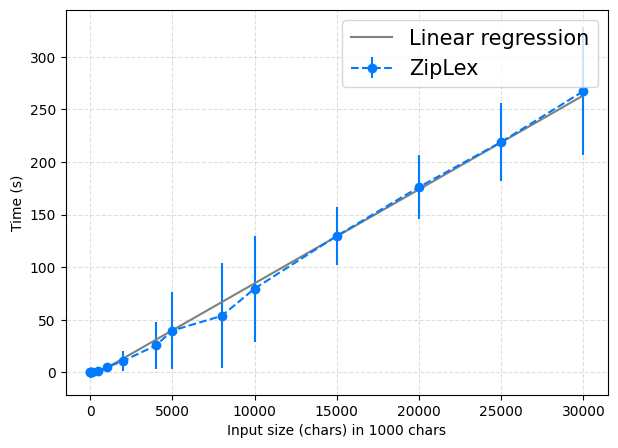

Polynomial function f(x) = 0.008935*x - 4.598


In [29]:
latest_folder = Path("./latest")
aastarb_big_lexer_file = None
for entry in os.listdir(latest_folder):
    if 'aa_star_b_lexer_benchmark_big' in entry.lower():
        aastarb_big_lexer_file = latest_folder / entry
        break
    
assert aastarb_big_lexer_file is not None, "Could not find aastarb_lexer benchmark file in 'latest' folder."
with open(aastarb_big_lexer_file, "r") as f:
    raw7 = f.read()
data7 = parse_jmh_table(raw7)
bench_aastarb_zipperMem = "BigAAStarBLexerBenchmark.lex_ZipperV3Mem"
d_aastarb_big_zipperMem_up_to_30_000KB = (bench_aastarb_zipperMem, [v for v in data7[bench_aastarb_zipperMem] if v[0] <= 30_000])

if bench_aastarb_zipperMem in data7:
    d_aastarb_big_zipperMem = (bench_aastarb_zipperMem, data7[bench_aastarb_zipperMem])
    plot_with_regression(d_aastarb_big_zipperMem_up_to_30_000KB,
                         degree=1,
                         title="a & a*b (large files): Lexing with Linear Regression (deg 1)",
                         filename="fig_6_right_a_aStarb_ziplex_large_files_linear_regression_up_to_30k.pdf",
                         show_title=False,
                         output_folder="plots",
                         pretty_data_labels={
                             bench_aastarb_zipperMem: "ZipLex"
                         },
                         fmt="pdf",
                         time_unit="s",
                         convert_data_from_micro_sec=True,
                         custom_additional_y_label=" in 1000 chars",
                         fontsize=15
                         )
    
else:
    print(f"Benchmark {bench_aastarb_zipperMem} not found in the latest data.")

# Hash Tables Benchmark Results 

In [30]:
from pathlib import Path
import os

if "parse_jmh_table" not in globals():
    raise RuntimeError("Please run the setup cells first (imports + parse_jmh_table + plotting helpers).")

latest_folder = Path("./latest")
hashmaps_benchmark_file = None
for entry in os.listdir(latest_folder):
    if "hashmap_benchmark" in entry.lower():
        hashmaps_benchmark_file = latest_folder / entry
        break

assert hashmaps_benchmark_file is not None, "Could not find hashmaps benchmark file in 'latest' folder."
with open(hashmaps_benchmark_file, "r") as f:
    raw_hashmaps = f.read()
data_hashmaps = parse_jmh_table(raw_hashmaps)

bench_verified_longmap = "MutableHashMapBenchmarkBig.createUpdateRemoveUpdateLookup_16Buffer_VerifiedMutableLongMap"
bench_scala_hashmap = "MutableHashMapBenchmarkBig.createUpdateRemoveUpdateLookup_16Buffer_OriginalHashMap"
bench_verified_hashmap = "MutableHashMapBenchmarkBig.createUpdateRemoveUpdateLookup_16Buffer_VerifiedHashMap"
bench_scala_immutable_hashmap = "MutableHashMapBenchmarkBig.createUpdateRemoveUpdateLookup_16Buffer_ImmutableHashMap"

required_benches = [
    bench_verified_longmap,
    bench_scala_hashmap,
    bench_verified_hashmap,
    bench_scala_immutable_hashmap,
]
missing = [b for b in required_benches if b not in data_hashmaps]
if missing:
    print("Missing benchmark series:")
    for b in missing:
        print(f"  - {b}")
    print("\nAvailable series:")
    for k in sorted(data_hashmaps.keys()):
        print(f"  - {k}")
else:
    pretty_labels = {
        bench_verified_longmap: "Verified LongMap",
        bench_scala_hashmap: "Scala HashMap",
        bench_verified_hashmap: "Verified HashMap",
        bench_scala_immutable_hashmap: "Scala Immutable HashMap",
    }

    plot4(
        (bench_verified_longmap, data_hashmaps[bench_verified_longmap]),
        (bench_scala_hashmap, data_hashmaps[bench_scala_hashmap]),
        (bench_verified_hashmap, data_hashmaps[bench_verified_hashmap]),
        (bench_scala_immutable_hashmap, data_hashmaps[bench_scala_immutable_hashmap]),
        title="HashMap_updateRemoveUpdate_Comparison",
        filename="fig_7_right_hashmap_update_remove_update_comparison",
        show_title=False,
        pretty_data_labels=pretty_labels,
        output_folder="plots",
        fmt="pdf",
        time_unit="s",
        convert_data_from_micro_sec=True,
        fontsize=15,
        shape_cycle=['o', 'x', 'P', '^'],
        error_bars=False,
        x_label="Number of entries"
    )

AssertionError: Could not find hashmaps benchmark file in 'latest' folder.

# Clement Regex Benchmark Results (Ranges vs no Ranges)

`RegexClementBenchmark`: `matchZipperSequenceMem` on 20 small patterns, on accepted strings of size 8 to 512. Each pattern is run in two variants on the same inputs:
- **no ranges**: the regexes before the refactoring to `ElementRange` (character classes are `ElementSet`s, unions of single characters are `Union`s of `ElementMatch`es)
- **ranges**: character classes, as well as `(x|y|z)` and `(a|...|p)`, are `ElementRange`s over `CharOrd`

For the patterns made of fixed words (p05-p08, p12), the input is the longest concatenation of words not exceeding the requested size.

In [31]:
from extract_regex_clement import PATTERNS as CLEMENT_PATTERNS

if "parse_jmh_table" not in globals():
    raise RuntimeError("Please run the setup cells first (imports + parse_jmh_table + plotting helpers).")

CLEMENT_VARIANTS = ["noRanges", "ranges"]
clement_labels = {"noRanges": "No ranges", "ranges": "Ranges"}
clement_markers = {"noRanges": "o", "ranges": "x"}

def find_latest_file(prefix: str) -> Path:
    """The file of the 'latest' folder whose name is `prefix` followed by `_wi_...`"""
    latest_folder = Path("./latest")
    matches = [latest_folder / e for e in os.listdir(latest_folder) if e.lower().startswith(prefix + "_wi_")]
    assert len(matches) == 1, f"Expected exactly one '{prefix}_wi_*' file in 'latest' folder, found {matches}"
    return matches[0]

def load_clement(file: Path, class_name: str) -> Dict[int, Dict[str, List[Tuple[int, Tuple[float, float]]]]]:
    """Returns res[pid] = {"noRanges": series, "ranges": series}, where series is a list of (size, (avg_us, error_us))"""
    with open(file, "r") as f:
        data = parse_jmh_table(f.read())
    res: Dict[int, Dict[str, List[Tuple[int, Tuple[float, float]]]]] = {}
    for bench, series in data.items():
        m = re.match(rf"{class_name}\.p(\d+)_\S+_(noRanges|ranges)$", bench)
        if m:
            res.setdefault(int(m.group(1)), {})[m.group(2)] = series
    missing = [(pid, v) for pid in range(len(CLEMENT_PATTERNS)) for v in CLEMENT_VARIANTS if v not in res.get(pid, {})]
    assert not missing, f"Missing (pid, variant) series in {file}: {missing}"
    return res

def clement_ratios(slow: Dict[int, List[Tuple[int, Tuple[float, float]]]],
                   fast: Dict[int, List[Tuple[int, Tuple[float, float]]]]) -> Dict[int, Dict[int, float]]:
    """ratios[pid][size] = time of `slow` / time of `fast` (> 1 means `fast` is faster), for the sizes present in both"""
    ratios = {}
    for pid in sorted(slow):
        s, f = dict(slow[pid]), dict(fast[pid])
        ratios[pid] = {size: s[size][0] / f[size][0] for size in sorted(s.keys() & f.keys())}
    return ratios

def print_clement_table(slow, fast, slow_label: str, fast_label: str):
    """Table of `slow -> fast (ratio)` in µs/op, one line per pattern and one column per size"""
    ratios = clement_ratios(slow, fast)
    sizes = sorted({size for r in ratios.values() for size in r})
    pattern_width = max(len(p) for p in CLEMENT_PATTERNS)
    header = f"{'pid':>3}  {'pattern':<{pattern_width}}" + "".join(f"{'size ' + str(s):>24}" for s in sizes)
    print(f"Time in µs/op: {slow_label} -> {fast_label} (speedup = time {slow_label} / time {fast_label}, > 1: {fast_label} is faster)")
    print(header)
    print("-" * len(header))
    for pid in sorted(ratios):
        s, f = dict(slow[pid]), dict(fast[pid])
        cells = "".join(f"{s[size][0]:>8.2f} ->{f[size][0]:>8.2f} ({ratios[pid][size]:.2f}x)".rjust(24) for size in sizes)
        print(f"{pid:>3}  {CLEMENT_PATTERNS[pid]:<{pattern_width}}{cells}")

def plot_clement_grid(results, filename: str):
    """One subplot per pattern: time vs input size, with and without ranges"""
    pids = sorted(results)
    ncols = 4
    nrows = (len(pids) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), sharex=True)
    for ax, pid in zip(axes.flat, pids):
        for i, variant in enumerate(CLEMENT_VARIANTS):
            xs, ys, yerr = _prep_xy(results[pid][variant])
            ax.errorbar(xs, ys, yerr=yerr, marker=clement_markers[variant], markersize=4, capsize=2,
                        color=_COLOR_CYCLE[i], label=clement_labels[variant])
        ax.set_title(f"p{pid:02d} {CLEMENT_PATTERNS[pid]}", fontsize=10)
        ax.grid(True, alpha=0.3)
    for ax in axes.flat[len(pids):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Input size (chars)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Time (µs)")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(CLEMENT_VARIANTS), bbox_to_anchor=(0.5, 1.02))
    fig.tight_layout()
    _ensure_save(fig, filename, fmt="pdf", output_folder="plots")
    plt.show()

def plot_clement_speedups(speedups_by_label: Dict[str, Dict[int, float]], title: str, y_label: str, filename: str):
    """Bar chart of speedups per pattern, one bar per entry of `speedups_by_label` (with a single entry, bars are
    colored by whether the speedup is >= 1)"""
    labels = list(speedups_by_label)
    pids = sorted(next(iter(speedups_by_label.values())))
    width = 0.8 / len(labels)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    for i, label in enumerate(labels):
        values = [speedups_by_label[label][pid] for pid in pids]
        xs = [j + (i - (len(labels) - 1) / 2) * width for j in range(len(pids))]
        if len(labels) == 1:
            ax.bar(xs, values, width=width, color=[_COLOR_CYCLE[0] if v >= 1 else _COLOR_CYCLE[2] for v in values])
        else:
            ax.bar(xs, values, width=width, color=_COLOR_CYCLE[i], label=label)
    if len(labels) > 1:
        ax.legend()
    ax.axhline(1.0, color="black", linewidth=1)
    ax.set_xticks(range(len(pids)))
    ax.set_xticklabels([f"p{pid:02d}\n{CLEMENT_PATTERNS[pid]}" for pid in pids], rotation=60, ha="right", fontsize=8)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.3)
    fig.tight_layout()
    _ensure_save(fig, filename, fmt="pdf", output_folder="plots")
    plt.show()

def speedups_of_ranges_at_largest(results) -> Dict[int, float]:
    ratios = clement_ratios({pid: results[pid]["noRanges"] for pid in results}, {pid: results[pid]["ranges"] for pid in results})
    return {pid: r[max(r)] for pid, r in ratios.items()}

def print_clement_ranges_table(results):
    print_clement_table({pid: results[pid]["noRanges"] for pid in results}, {pid: results[pid]["ranges"] for pid in results},
                        "no ranges", "ranges")

In [32]:
clement = load_clement(find_latest_file("regex_clement_benchmark"), "RegexClementBenchmark")
print_clement_ranges_table(clement)

Time in µs/op: no ranges -> ranges (speedup = time no ranges / time ranges, > 1: ranges is faster)
pid  pattern                               size 8                size 176                size 344                size 512
-------------------------------------------------------------------------------------------------------------------------
  0  [a-z]+                  0.62 ->    0.57 (1.08x)   16.02 ->   15.69 (1.02x)   31.68 ->   30.64 (1.03x)   45.92 ->   45.28 (1.01x)
  1  [a-z][a-z0-9]*          0.61 ->    0.56 (1.10x)   14.94 ->   15.24 (0.98x)   30.34 ->   30.91 (0.98x)   44.32 ->   44.62 (0.99x)
  2  [0-9]+                  0.62 ->    0.60 (1.03x)   15.45 ->   15.61 (0.99x)   29.49 ->   29.69 (0.99x)   42.12 ->   47.76 (0.88x)
  3  [a-z0-9]+               0.55 ->    0.60 (0.91x)   14.86 ->   15.39 (0.97x)   29.46 ->   29.58 (1.00x)   46.51 ->   45.03 (1.03x)
  4  [a-z]+@[a-z]+           0.71 ->    0.62 (1.16x)   16.33 ->   16.31 (1.00x)   36.52 ->   35.14 (1.04x)   44.43 ->   4

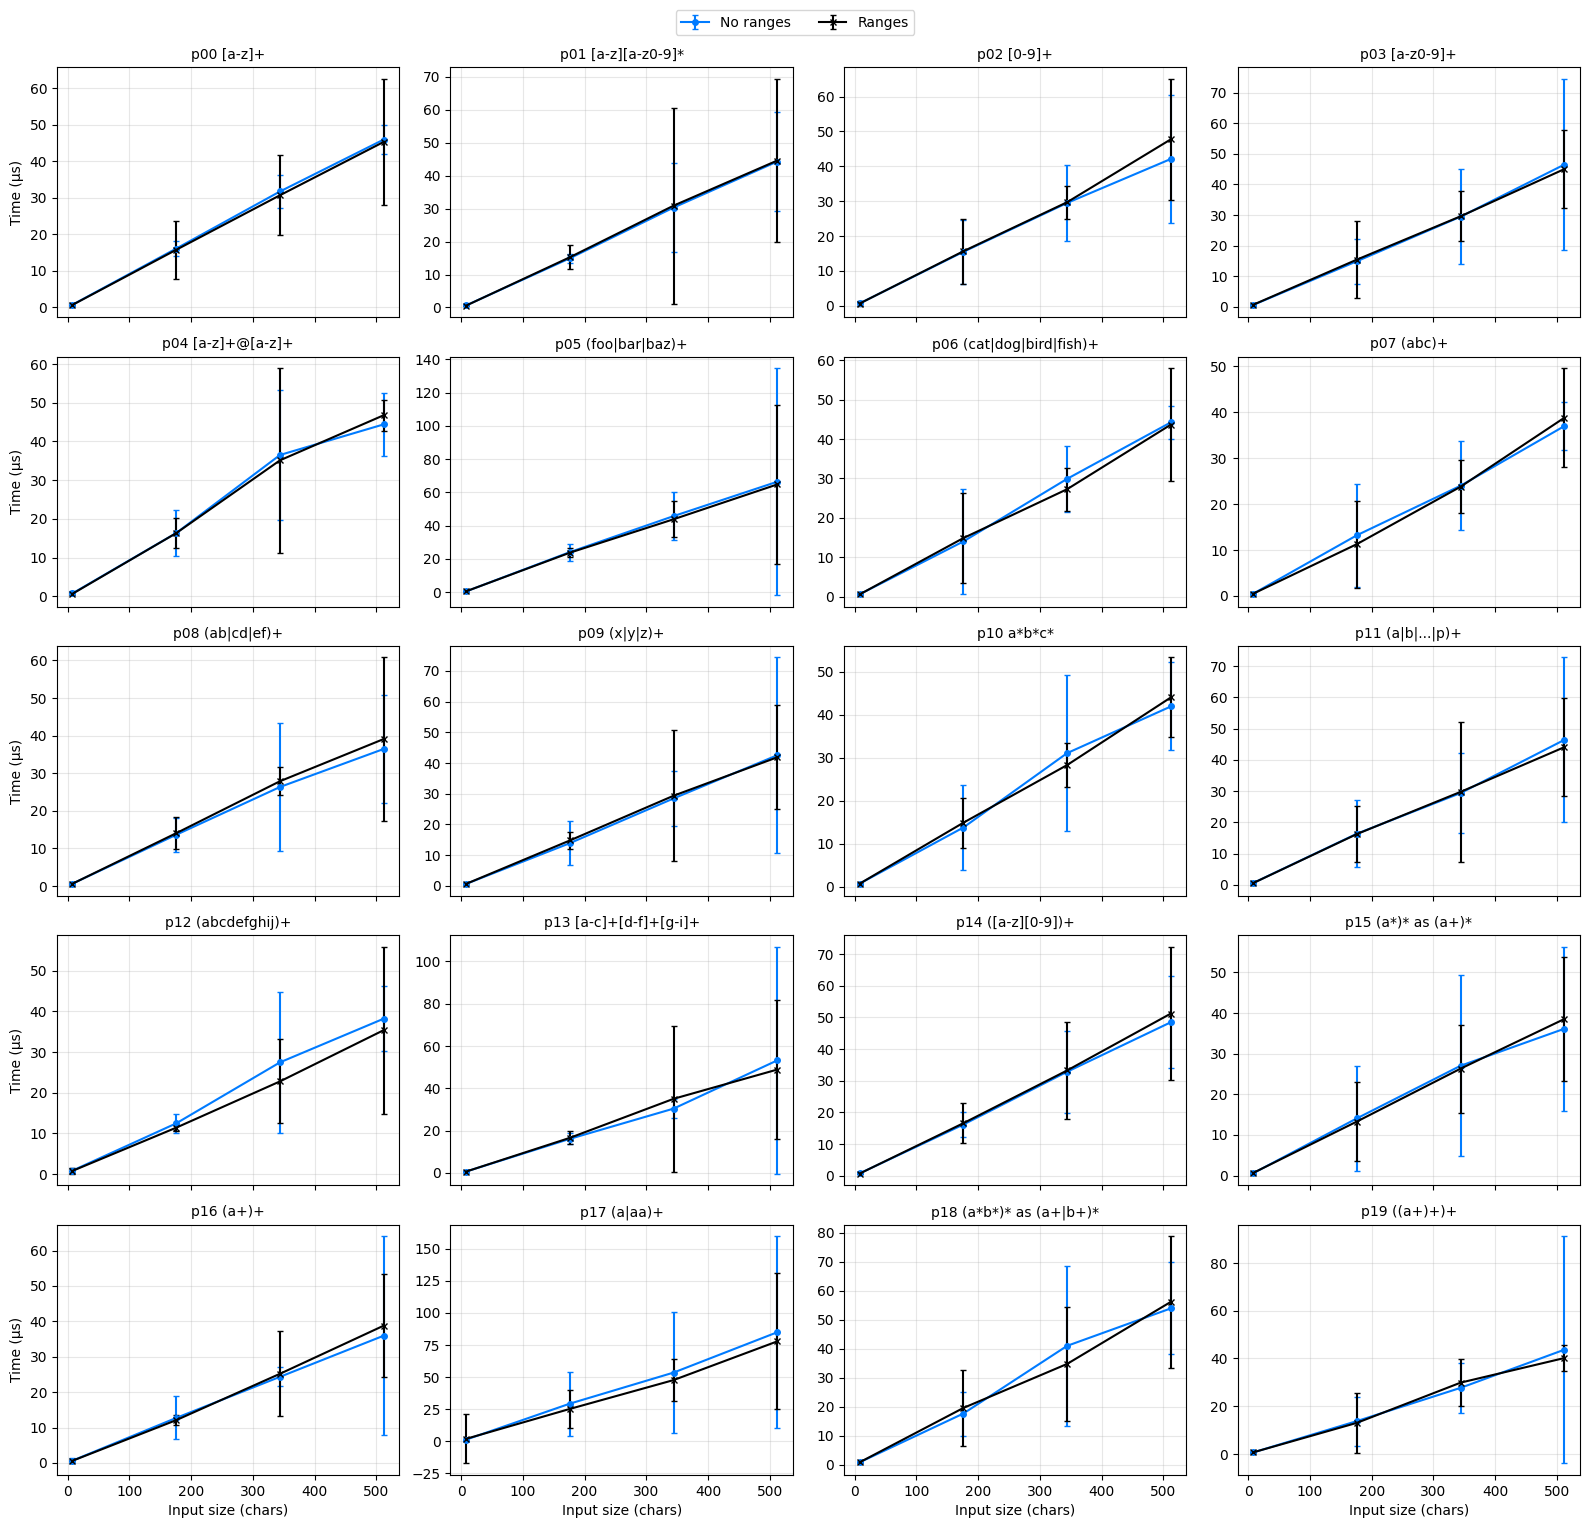

In [33]:
plot_clement_grid(clement, "regex_clement_ranges_vs_no_ranges_per_pattern")

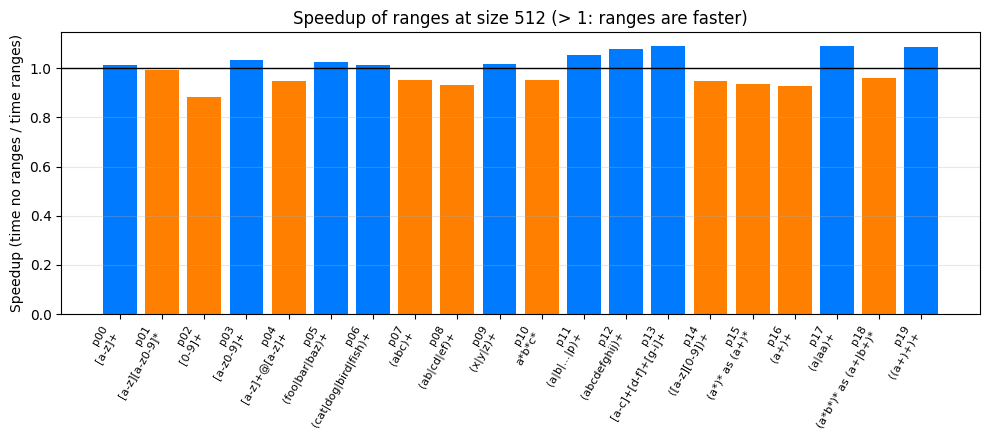

In [34]:
# Speedup of ranges over no ranges at the largest input size
clement_largest = max(size for size, _ in clement[0]["ranges"])
plot_clement_speedups({"ranges": speedups_of_ranges_at_largest(clement)},
                      title=f"Speedup of ranges at size {clement_largest} (> 1: ranges are faster)",
                      y_label="Speedup (time no ranges / time ranges)",
                      filename="regex_clement_ranges_speedup")

## Without memoization

`RegexClementNoMemBenchmark`: same patterns, variants and inputs, but with the non-memoized matcher `matchZipperSequence`.

In [35]:
clement_no_mem = load_clement(find_latest_file("regex_clement_benchmark_no_mem"), "RegexClementNoMemBenchmark")
print_clement_ranges_table(clement_no_mem)

Time in µs/op: no ranges -> ranges (speedup = time no ranges / time ranges, > 1: ranges is faster)
pid  pattern                             size 512
-------------------------------------------------
  0  [a-z]+                 20.93 ->   17.97 (1.16x)
  1  [a-z][a-z0-9]*         21.04 ->   33.12 (0.64x)
  2  [0-9]+                 20.27 ->   18.69 (1.08x)
  3  [a-z0-9]+              21.00 ->   30.90 (0.68x)
  4  [a-z]+@[a-z]+          23.48 ->   22.20 (1.06x)
  5  (foo|bar|baz)+         52.30 ->   44.14 (1.18x)
  6  (cat|dog|bird|fish)+   30.67 ->   30.46 (1.01x)
  7  (abc)+                 14.54 ->   15.10 (0.96x)
  8  (ab|cd|ef)+            31.96 ->   37.44 (0.85x)
  9  (x|y|z)+               46.88 ->   17.70 (2.65x)
 10  a*b*c*                 43.73 ->   50.64 (0.86x)
 11  (a|b|...|p)+          292.51 ->   18.59 (15.74x)
 12  (abcdefghij)+          11.69 ->   18.26 (0.64x)
 13  [a-c]+[d-f]+[g-i]+     40.72 ->   26.81 (1.52x)
 14  ([a-z][0-9])+          19.68 ->   17.86 (1.10x)
 15  

In [36]:
clement_no_mem_sizes = sorted({size for size, _ in clement_no_mem[0]["ranges"]})
if len(clement_no_mem_sizes) > 1:
    plot_clement_grid(clement_no_mem, "regex_clement_no_mem_ranges_vs_no_ranges_per_pattern")
else:
    print(f"Only one input size ({clement_no_mem_sizes}) in the no-mem results, skipping the time vs size plot.")

Only one input size ([512]) in the no-mem results, skipping the time vs size plot.


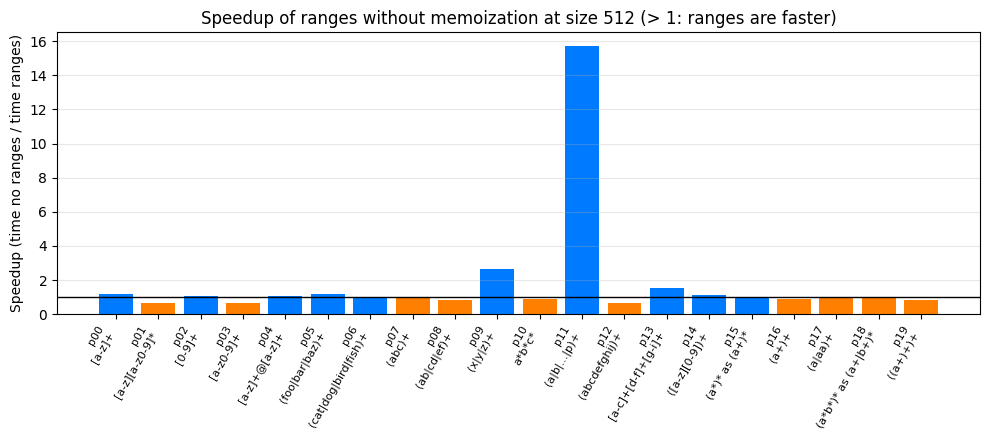

In [37]:
# Speedup of ranges over no ranges at the largest input size, without memoization
clement_no_mem_largest = max(size for size, _ in clement_no_mem[0]["ranges"])
plot_clement_speedups({"ranges": speedups_of_ranges_at_largest(clement_no_mem)},
                      title=f"Speedup of ranges without memoization at size {clement_no_mem_largest} (> 1: ranges are faster)",
                      y_label="Speedup (time no ranges / time ranges)",
                      filename="regex_clement_no_mem_ranges_speedup")

## Memoization vs no memoization

Speedup of the memoized matcher over the non-memoized one, per pattern and variant (> 1 means memoization is faster).

In [ ]:
for variant in CLEMENT_VARIANTS:
    print_clement_table({pid: clement_no_mem[pid][variant] for pid in clement_no_mem},
                        {pid: clement[pid][variant] for pid in clement},
                        f"no mem ({clement_labels[variant]})", f"mem ({clement_labels[variant]})")
    print()

# At the largest size present in both suites
mem_speedups = {}
for variant in CLEMENT_VARIANTS:
    ratios = clement_ratios({pid: clement_no_mem[pid][variant] for pid in clement_no_mem},
                            {pid: clement[pid][variant] for pid in clement})
    mem_speedups[clement_labels[variant]] = {pid: r[max(r)] for pid, r in ratios.items()}
common_largest = min(clement_largest, clement_no_mem_largest)
plot_clement_speedups(mem_speedups,
                      title=f"Speedup of memoization at size {common_largest} (> 1: memoization is faster)",
                      y_label="Speedup (time no mem / time mem)",
                      filename="regex_clement_mem_speedup")

# Stainless verification

In [ ]:
import shutil
import os
import json

verif_report_file = None
for entry in os.listdir(latest_folder):
    if 'verification-report' in entry.lower():
        verif_report_file = latest_folder / entry
        break
  
assert verif_report_file is not None, "Could not find verification report file in 'latest' folder."
with open(verif_report_file, "r") as f:
    verif_report = json.load(f)
  

def get_smt_solver(vc: dict) -> Optional[str]:
    """Extract the SMT solver used from the verification condition dictionary."""
    if "solverName" not in vc or vc["solverName"] is None:
        return None
    return vc["solverName"].replace("U:", "").replace("smt-", "")
def get_smt_id(vc: dict) -> str:
    """Extract the SMT solver ID from the verification condition dictionary."""
    return vc["smtId"]
def get_time_ms(vc: dict) -> float:
    """Extract the time taken (in milliseconds) from the verification condition dictionary."""
    return vc["time"]
def get_time_s(vc: dict) -> float:
    """Extract the time taken (in seconds) from the verification condition dictionary."""
    return vc["time"] / 1000.0
def get_status(vc: dict) -> str:
    """Extract the status of the verification condition."""
    return list(vc["status"].keys())[0].lower()

def filter_out_smt_queries(vcs: list[dict], smt_queries_directory_src: str, smt_queries_directory_dst: Optional[str] = None):
    """
    Goes through the smt-lib files in smt_queries_directory_src and removes smt queries that are not
    for the solver that solved the VC. We need to do this because the solvers are run in parallel, 
    and we want to keep only the smt lib files for the solver that solved the VC.
    Delete the files in place, or if smt_queries_directory_dst is provided, copy the files to that are kept in that directory.
    """
    smt_id_to_solver = {}
    for vc in vcs:
        smt_id = get_smt_id(vc)
        solver = get_smt_solver(vc)
        smt_id_to_solver[smt_id] = solver
    
    # go through the directory
    for file_name in os.listdir(smt_queries_directory_src):
        if file_name.endswith(".smt2"):
            smt_id_in_file = int(file_name.split("-")[-1].replace(".smt2", ""))
            if smt_id_in_file in smt_id_to_solver:
                solver_for_vc = smt_id_to_solver[smt_id_in_file]
                if solver_for_vc.lower() in file_name.lower():
                    # copy the file
                    if smt_queries_directory_dst is not None:
                        os.makedirs(smt_queries_directory_dst, exist_ok=True)
                        # copy the file to the dst directory
                        shutil.copy(os.path.join(smt_queries_directory_src, file_name), os.path.join(smt_queries_directory_dst, file_name))

            else:
                print(f"SMT ID {smt_id_in_file} not found in VCs.")
                os.remove(os.path.join(smt_queries_directory_src, file_name))



vcs = verif_report["stainless"][0][1][0]
try:
    filter_out_smt_queries(vcs, "../smt-sessions", "./latest/smt-sessions-filtered")
    print(f"After filtering, number of SMT files: {len(os.listdir('./latest/smt-sessions-filtered'))}")
except Exception as e:
    print(f"An error occurred: {e}")

NameError: name 'latest_folder' is not defined

In [ ]:
print(f"Total number of VCs: {len(vcs)}")
trivial_vcs = [vc for vc in vcs if get_status(vc) == "trivial"]
print(f"Number of trivial VCs: {len(trivial_vcs)}")
valid_from_cache_vcs  = [vc for vc in vcs if get_status(vc) == "validfromcache"]
print(f"Number of valid from cache VCs: {len(valid_from_cache_vcs)}")
valid_vcs = [vc for vc in vcs if get_status(vc) == "valid"]
print(f"Number of valid VCs: {len(valid_vcs)}")

valid_vcs_time_s = [get_time_s(vc) for vc in valid_vcs]
plot_distribution(valid_vcs_time_s,
                  title="Distribution of Verification Times for VCs",
                  x_label="Time (s)",
                  y_label="Frequency",
                  bins=50,
                  log_scale=True,
                  filename="vc_verification_times_distribution",
                  output_folder="plots",
                  fmt="pdf"
                  )

vcs_slower_than_10s = [vc for vc in valid_vcs if get_time_s(vc) > 10.0]
# sort by time descending
vcs_slower_than_10s.sort(key=get_time_s, reverse=True)

print(f"Number of valid VCs slower than 10s: {len(vcs_slower_than_10s)}")
print("\n\n")
for vc in vcs_slower_than_10s:
    print(f"SMT ID: {get_smt_id(vc)}, Solver: {get_smt_solver(vc)}, Time (s): {get_time_s(vc)}")


total_verification_time_s = sum(get_time_s(vc) for vc in vcs)
print("\n")
print(f"Total verification time for all VCs: {total_verification_time_s} seconds")


NameError: name 'vcs' is not defined